In [1]:
import sys
from pathlib import Path

# SAGE is not installed in this kernel: put the SAGE repo (the folder that holds sage/) on the path
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sage" / "__init__.py").exists()), None)
if root is None:
    raise RuntimeError("SAGE repo not found above " + str(Path.cwd()) + ": run the notebook from inside it")
sys.path.insert(0, str(root))

import torch
from gwpy.timeseries import TimeSeries
import pandas as pd
import matplotlib.pyplot as plt
from sage.data.noise import sample_synthetic_noise
from sage.dsp.qtransform import QTransform

/cvmfs/software.igwn.org/conda/envs/igwn-py311/lib/python3.11/site-packages/gwpy/time/__init__.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


In [2]:
file = 'O3b_vigilant_train_set.csv'
df = pd.read_csv(file)
len(df['GPStime'])

11193

In [9]:
start, end = df['GPStime'].iloc[0] - 20, df['GPStime'].iloc[0] + 20
data = TimeSeries.get('V1:Hrec_hoft_16384Hz', start, end, frametype='HoftOnline')

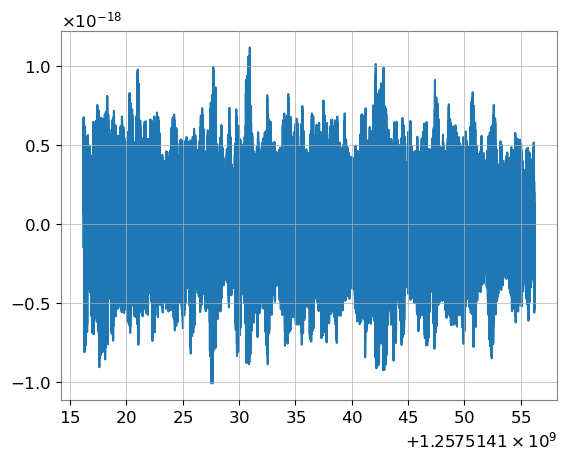

In [10]:
plt.plot(data)

In [ ]:
%%time
# SAGE Q-transform around the glitch: whiten with gwpy, then SAGE's QTransform, with gwpy's settings
# for a window around an event: q_transform(outseg=..., logf=True) -> 1000 times x 500 frequencies
fs = 4096
t0 = df['GPStime'].iloc[0]
white = data.resample(fs).whiten(fduration=10)         # ASD estimated from these 40 s
white = white.crop(start + 10, end - 10)                # drop 10 s at each end (the whitening corrupts fduration / 2 = 5 s)
x = torch.tensor(white.value)
tc = t0 - white.t0.value                                # glitch time, in s from the start of x

qt = QTransform(fs, x.numel(), qrange=(4, 64), frange=(20, 1000), logf=True, fres=500,
                outseg=(tc - 1, tc + 1))               # 1000 samples over the 2 s window, as gwpy
qscan, q = qt(x, gps=tc, return_q=True)                # Q chosen within +/- 0.25 s of the glitch, as gwpy's gps=

fig, ax = plt.subplots(figsize=(10, 4))
ax.pcolormesh(qt.times - tc, qt.frequencies, qscan.T, shading="auto", vmin=0, vmax=25)
ax.set(yscale="log", xlabel=f"time from {t0} [s]", ylabel="frequency [Hz]",
       title=f"SAGE Q-transform, Q = {float(q):.1f}")

# the same with gwpy, for comparison. Times from 0, as in SAGE: on GPS times (~1.3e9 s) gwpy's own
# output times drift by up to ~1e-4 s (float64 rounding), which changes its image by ~0.4% near a glitch
ref = TimeSeries(white.value, sample_rate=fs).q_transform(whiten=False, qrange=(4, 64), frange=(20, 1000),
                                                          logf=True, gps=tc, outseg=(tc - 1, tc + 1))
print(f"gwpy Q = {ref.q:.1f}, largest difference from SAGE = {abs(qscan.numpy() - ref.value).max() / ref.value.max():.1e} of the peak")